# 06e. Case study: the summer 2012 central U.S. heat wave: S2S lead-window verification

Regional-mean TREFHT averaged over the lead windows `lead_windows` (lead 1 = the start date) of each start, against ERA5 on the same days: ensemble-mean error, member spread and CRPS. With `none` these are scores of the absolute temperature (primary); with `amip` of the AMIP-reference anomaly against the observed anomaly (supplementary). Shaded windows overlap the observed event for that start.

**The 06a-06h series** (summer 2012 central U.S. heat wave; each notebook reads the data it needs, computes, saves, then plots): `06a` observed event and simulation coverage; `06b` experiment QC; `06c` start-resolved regional trajectories; `06d` fixed-event-window metrics and maps; `06e` S2S lead-window scores; `06f` event probability; `06g` initialization contrasts; `06h` sensitivity of the event definition. Settings: `HeatwaveSettings` in `configs/hind_lead_eval_cases.py`; products: `util/heatwave_workflow.py`; methods: `util/heatwave_case.py`. Design, event definition and reference states: `06a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/heatwave_2012/lead_window_scores.csv`; figures `heatwave_lead_scores_<BIAS>.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the HeatwaveSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"event_window": ("2012-06-27", "2012-07-07")}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import HeatwaveSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.heatwave_workflow import HeatwaveCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = HeatwaveCase(HeatwaveSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012
[SCORED] ['CLIM_BASE', 'DA_COUPLED', 'DA_ATM']
[QC ONLY] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies and the calendar-day thresholds (`observed_fields.nc`), and from them the observed events and the event window. Then the daily TREFHT (mean of the four 6-hour means) and PRECT of every member on the map box (`box_<CONFIG>_<SEASON>_<VAR>.nc`), put on calendar days, and their regional means: absolute temperature, anomalies against both references (`biases`), area fraction above the gridpoint threshold, and precipitation (daily and accumulated from the start).

In [4]:
obs = case.obs
print(f"[REGION] {cfg.region['name']}: {int(obs.mask.sum())} land points\n[CLIM] observed: {obs.clim_sources[0]}\n"
      f"[CLIM] model: {obs.clim_sources[1]}")
series = case.series

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/observed_fields.nc
[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[REGION] CENTRAL_US: 200 land points
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))


[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[SERIES] 20 (config, start) pairs, 40 anomaly series


## 5. Process and save

Window means, ensemble-mean error, member spread and CRPS of every configuration, start and lead window (`lead_window_scores.csv`); shown: CRPS of the scored configurations.

In [5]:
from util.heatwave_workflow import REFERENCE_LABELS

lead_scores = case.lead_scores()
ls = lead_scores[lead_scores.config.isin(case.scored)]
for b in cfg.biases:
    print(f"CRPS (K), {REFERENCE_LABELS[b]}:")
    display(ls[ls.bias == b].pivot(index=["init", "window"], columns="config", values="crps")[case.scored].round(2))

[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/lead_window_scores.csv: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/lead_window_scores.csv
CRPS (K), observed-reference anomalies, no mean-bias adjustment (differences = absolute error):


config                CLIM_BASE  DA_COUPLED  DA_ATM
init       window                                  
2012-05-16 week 1          4.75        0.16    0.14
           week 2          4.29        0.39    0.72
           weeks 3-4       0.36        0.52    0.53
           weeks 5-6       1.79        0.44    0.61
           weeks 7-8       1.85        1.44    1.21
2012-05-21 week 1          4.38        0.14    0.15
           week 2          0.60        1.10    1.51
           weeks 3-4       0.94        0.40    0.41
           weeks 5-6       1.61        1.63    0.55
           weeks 7-8       0.66        0.27    0.50
2012-05-26 week 1          2.92        0.14    0.13
           week 2          0.83        0.62    0.56
           weeks 3-4       1.43        0.41    0.45
           weeks 5-6       2.76        2.52    2.12
           weeks 7-8       0.31        0.38    0.49
2012-05-31 week 1          0.52        0.83    1.19
           week 2          1.90        0.48    0.46
           weeks 3-4       1.34        0.61    0.48
           weeks 5-6       1.72        1.19    1.01
           weeks 7-8       1.20        0.29    0.61

CRPS (K), AMIP-reference anomalies (AMIP mean bias removed; drift kept):


config                CLIM_BASE  DA_COUPLED  DA_ATM
init       window                                  
2012-05-16 week 1          4.79        0.18    0.16
           week 2          4.38        0.43    0.76
           weeks 3-4       0.42        0.49    0.49
           weeks 5-6       2.30        0.70    0.87
           weeks 7-8       3.23        2.76    2.61
2012-05-21 week 1          4.45        0.12    0.14
           week 2          0.66        1.00    1.40
           weeks 3-4       1.09        0.48    0.53
           weeks 5-6       2.30        2.48    1.10
           weeks 7-8       2.07        1.32    1.45
2012-05-26 week 1          3.03        0.16    0.13
           week 2          0.94        0.70    0.63
           weeks 3-4       1.79        0.64    0.56
           weeks 5-6       3.93        3.69    3.22
           weeks 7-8       1.97        1.39    1.04
2012-05-31 week 1          0.65        0.70    1.05
           week 2          2.08        0.42    0.38
           weeks 3-4       1.83        0.77    0.34
           weeks 5-6       3.17        2.57    2.31
           weeks 7-8       3.26        1.49    2.44

## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_lead_scores_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_lead_scores_amip.png


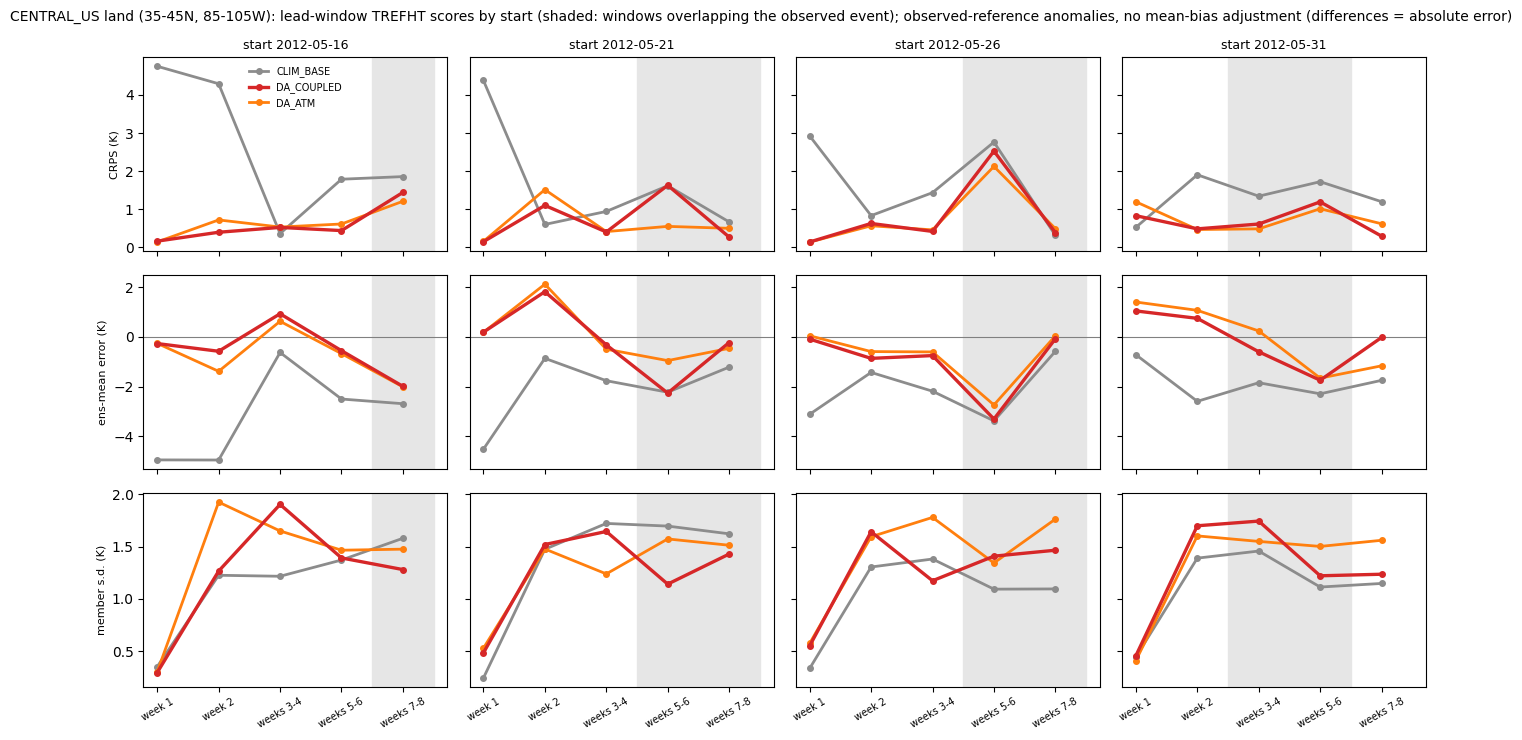

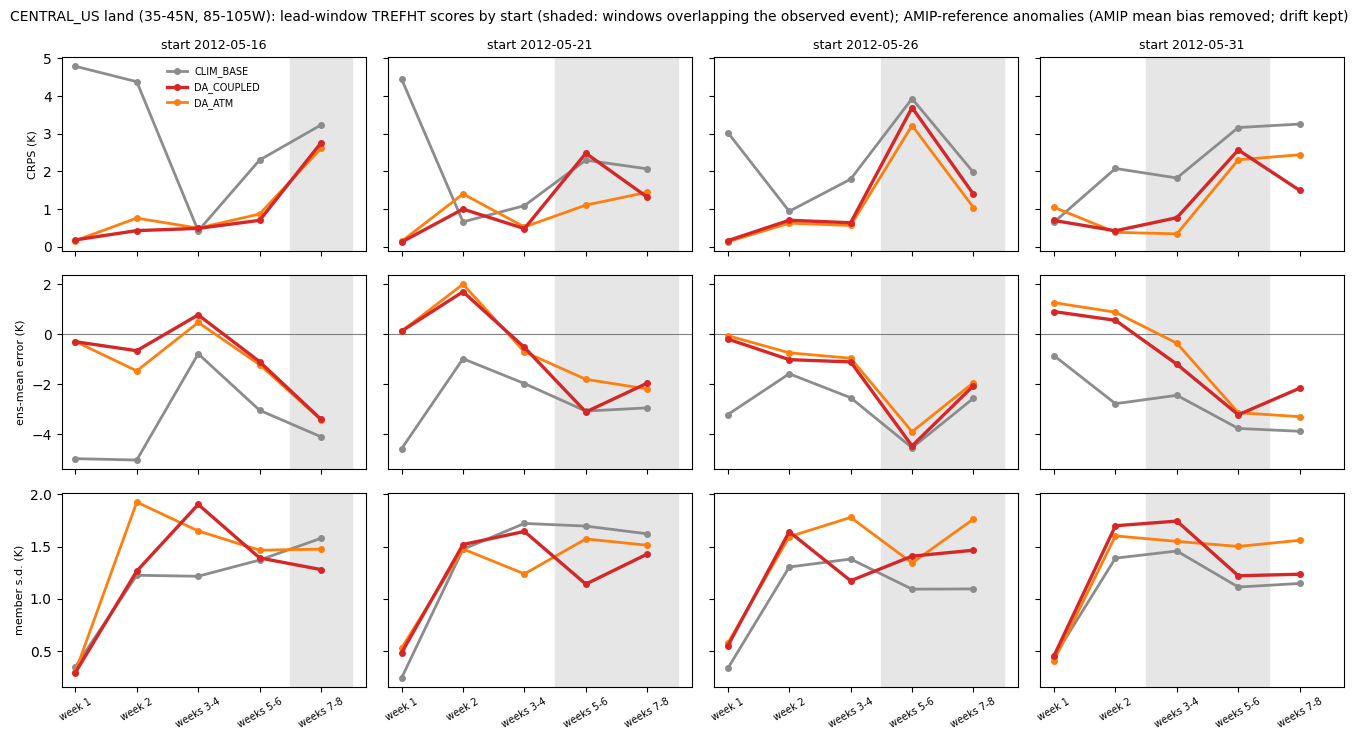

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.heatwave_case import plot_lead_scores

for b in cfg.biases:
    save(plot_lead_scores(ls[ls.bias == b], case.scored, STYLE_MAP,
                          {"crps": "CRPS (K)", "ens_mean_error": "ens-mean error (K)", "spread": "member s.d. (K)"},
                          event_leads=obs.event_leads,
                          title=f"{case.label}: lead-window TREFHT scores by start (shaded: windows overlapping the "
                                f"observed event); {REFERENCE_LABELS[b]}"),
         f"heatwave_lead_scores_{b}.png")